# Week 4b — State Source Expansion: JalanJalanMY

This notebook covers **all 13 states and 3 federal territories**.

**What this notebook does**
1. **Topic 3 steps** on 18 new official sources: Tourism Malaysia *Malaysia Travel Guide 2023* state chapters for Melaka, Penang and Sabah (S03–S05) and for the other 12 states and federal territories (S09–S20), plus the Penang, Melaka and Sabah *Map & Guide* leaflets (S06–S08). It uses the same extraction, cleaning and **paragraph-aware 500-character** chunking as Topic 3, plus two additions: **page numbers are kept** (Topic 4 condition 4), and a **map-label filter** is applied to the map guides.
2. **Topic 4 checks** with the same rules: ligature repair, glyph-ID quarantine, length review, approved sources, page reference, source age.
3. **Merge** with the reviewed KL corpus (`prepared_chunks_clean.jsonl`, 247 chunks) into **corpus v2**, deduplicate and measure coverage by state.

The original `week3_pipeline.ipynb` and `week4_quality.ipynb` are left unchanged as the lab record.

**Upload to Colab:** `MTG_2023.pdf`, `Map_Guide_PENANG_Eng.pdf`, `Melaka_Map_Guide_IDB_small.pdf`, `Sabah Map & Guide.pdf`, and `data/prepared_chunks_clean.jsonl` from the repo. Then use Runtime → Run all.

> The source PDFs are © Tourism Malaysia (all rights reserved). Coursework use only — not committed to the repository.

In [1]:
!pip install -q "pypdf==6.17.0"

## 1 — Setup and source check

In [2]:
!pip install -q "pypdf==6.17.0" pandera langchain-core matplotlib   # newer pypdf (6.19+) stops on the map guides with LimitReachedError
import os, re, json, shutil, pickle, hashlib
from pathlib import Path
from datetime import date
import pandas as pd

BASE = Path('/content')
RAW = BASE / 'states_raw'; RAW.mkdir(exist_ok=True)
(BASE / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
(BASE / 'docs').mkdir(exist_ok=True)

NEEDED = ['MTG_2023.pdf', 'Map_Guide_PENANG_Eng.pdf', 'Melaka_Map_Guide_IDB_small.pdf', 'Sabah Map & Guide.pdf']
for name in NEEDED:                                    # move uploads from /content into states_raw
    if (BASE / name).is_file() and not (RAW / name).is_file():
        shutil.move(str(BASE / name), str(RAW / name))
missing = [n for n in NEEDED if not (RAW / n).is_file()]
assert not missing, f'Upload these PDFs first: {missing}'
KL_CLEAN = BASE / 'prepared_chunks_clean.jsonl'
if not KL_CLEAN.exists() and (BASE / 'data' / 'prepared_chunks_clean.jsonl').exists():
    shutil.copy(BASE / 'data' / 'prepared_chunks_clean.jsonl', KL_CLEAN)
assert KL_CLEAN.exists(), 'Upload data/prepared_chunks_clean.jsonl (Topic 4 reviewed KL corpus) first.'
print('All inputs present:', NEEDED + [KL_CLEAN.name])


All inputs present: ['MTG_2023.pdf', 'Map_Guide_PENANG_Eng.pdf', 'Melaka_Map_Guide_IDB_small.pdf', 'Sabah Map & Guide.pdf', 'prepared_chunks_clean.jsonl']


In [3]:
# Shared preparation logic for the state-source expansion (same methods as Topic 3 / Topic 4).
# Usage: python3 -I prep_lib.py <src_dir> <out_jsonl>   (exploration run)
import re, json, hashlib, sys
from pathlib import Path
from pypdf import PdfReader

SOURCES = [  # (source_id, file, state, first_page, last_page, kind)
    ("S03", "MTG_2023.pdf", "Melaka", 53, 63, "guide-chapter"),
    ("S04", "MTG_2023.pdf", "Penang", 89, 99, "guide-chapter"),
    ("S05", "MTG_2023.pdf", "Sabah", 159, 179, "guide-chapter"),
    ("S06", "Map_Guide_PENANG_Eng.pdf", "Penang", 1, 2, "map-guide"),
    ("S07", "Melaka_Map_Guide_IDB_small.pdf", "Melaka", 1, 2, "map-guide"),
    ("S08", "Sabah Map & Guide.pdf", "Sabah", 1, 2, "map-guide"),
    ("S09", "MTG_2023.pdf", "Selangor", 23, 31, "guide-chapter"),
    ("S10", "MTG_2023.pdf", "Putrajaya", 33, 40, "guide-chapter"),
    ("S11", "MTG_2023.pdf", "Negeri Sembilan", 43, 51, "guide-chapter"),
    ("S12", "MTG_2023.pdf", "Johor", 65, 76, "guide-chapter"),
    ("S13", "MTG_2023.pdf", "Perak", 79, 87, "guide-chapter"),
    ("S14", "MTG_2023.pdf", "Kedah", 101, 111, "guide-chapter"),
    ("S15", "MTG_2023.pdf", "Perlis", 113, 118, "guide-chapter"),
    ("S16", "MTG_2023.pdf", "Pahang", 121, 131, "guide-chapter"),
    ("S17", "MTG_2023.pdf", "Terengganu", 133, 145, "guide-chapter"),
    ("S18", "MTG_2023.pdf", "Kelantan", 147, 158, "guide-chapter"),
    ("S19", "MTG_2023.pdf", "Sarawak", 181, 195, "guide-chapter"),
    ("S20", "MTG_2023.pdf", "Labuan", 197, 205, "guide-chapter"),
]
PHONE = re.compile(r'\+?6?0\d[\d\s-]{6,}')

def keep_line(line):
    """Map-label filter: keep sentence lines, phone lines and long upper-case headings."""
    l = line.strip()
    words = re.findall(r"[A-Za-z']+", l)
    return len(words) >= 4 or bool(PHONE.search(l)) or (len(words) >= 2 and l.isupper() and len(l) >= 8)

def fixed_chunks(s, size=500):          # Topic 3, unchanged
    if size <= 0:
        raise ValueError("Chunk size must be positive")
    return [s[i:i + size] for i in range(0, len(s), size)]

def paragraph_chunks(s, size=500):      # Topic 3, unchanged
    if size <= 0:
        raise ValueError("Chunk size must be positive")
    parts, current = [], ""
    for segment in re.split(r"\n\s*\n", s):
        segment = segment.strip()
        if not segment:
            continue
        if len(segment) > size:
            if current:
                parts.append(current); current = ""
            parts.extend(fixed_chunks(segment, size))
        elif len(current) + len(segment) + (2 if current else 0) <= size:
            current += ("\n\n" if current else "") + segment
        else:
            if current:
                parts.append(current)
            current = segment
    if current:
        parts.append(current)
    return parts

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def prepare(src_dir):
    src_dir = Path(src_dir); records, stats = [], []
    for sid, fname, state, a, b, kind in SOURCES:
        path = src_dir / fname; reader = PdfReader(str(path)); digest = sha256(path)
        n_lines = n_kept = 0; chars = 0
        for p in range(a, b + 1):
            text = reader.pages[p - 1].extract_text() or ""
            chars += len(text)
            if kind == "map-guide":
                lines = [l for l in text.splitlines() if l.strip()]
                kept = [l for l in lines if keep_line(l)]
                n_lines += len(lines); n_kept += len(kept)
                text = "\n".join(kept)
            clean = re.sub(r"[ \t]+", " ", text).strip()
            for n, chunk in enumerate(paragraph_chunks(clean, 500)):
                records.append({
                    "record_id": f"{sid}-p{p}-{n:03d}", "text": chunk, "source": fname,
                    "source_id": sid, "state": state, "page": p, "source_sha256": digest,
                    "processing": "paragraph-aware-char-500" + ("+map-label-filter" if kind == "map-guide" else ""),
                })
        stats.append({"source_id": sid, "file": fname, "state": state, "pages": f"{a}-{b}", "kind": kind,
                      "extracted_chars": chars, "map_lines": n_lines, "map_lines_kept": n_kept,
                      "chunks": sum(1 for r in records if r["source_id"] == sid)})
    return records, stats

# Source inspection: pages, readable text, glyph-ID and ligature artefacts, PDF dates
from pypdf import PdfReader
inspect_rows = []
for sid, fname, state, a, b, kind in SOURCES:
    reader = PdfReader(str(RAW / fname))
    text = '\n'.join(reader.pages[p - 1].extract_text() or '' for p in range(a, b + 1))
    meta = reader.metadata or {}
    inspect_rows.append({'source_id': sid, 'file': fname, 'state': state, 'pages': f'{a}-{b}', 'kind': kind,
                         'chars': len(text), 'glyph_id_codes': len(re.findall(r'/gid\d{5}', text)),
                         'ligature_artefacts': len(re.findall(r'/f_|[ﬀ-ﬆ]', text)),
                         'pdf_modified': str(meta.get('/ModDate', ''))[2:10],
                         'sha256': sha256(RAW / fname)[:12]})
inspection = pd.DataFrame(inspect_rows)
print(inspection.to_string(index=False))


source_id                           file           state   pages          kind  chars  glyph_id_codes  ligature_artefacts pdf_modified       sha256
      S03                   MTG_2023.pdf          Melaka   53-63 guide-chapter  15620               0                   0     20250528 7b1830e31301
      S04                   MTG_2023.pdf          Penang   89-99 guide-chapter  17575               0                   0     20250528 7b1830e31301
      S05                   MTG_2023.pdf           Sabah 159-179 guide-chapter  21165               0                   1     20250528 7b1830e31301
      S06       Map_Guide_PENANG_Eng.pdf          Penang     1-2     map-guide  39446               0                   6     20240314 1f956c184ebb
      S07 Melaka_Map_Guide_IDB_small.pdf          Melaka     1-2     map-guide  30277               0                   1     20240208 253d2ec35fd8
      S08          Sabah Map & Guide.pdf           Sabah     1-2     map-guide  33058               0           

**Inspection findings:**
- **Guide chapters (S03–S05, S09–S20):** readable prose, no glyph-ID text. Each range starts on the state's own introduction page and ends on its last page (transport or contacts), e.g. 53–63 (Melaka), 89–99 (Penang), 159–179 (Sabah), 23–31 (Selangor), 181–195 (Sarawak). Excluded on purpose: the full-page photo before each chapter, the regional introduction pages that describe several states at once (pp. 41, 77, 119), the Klang Valley transit map (p. 21, glyph-ID text) and the guide's **Kuala Lumpur chapter (pp. 7–20)**, because KL already has its own 72-page guide (S01) and the largest share of the corpus.
- **Map guides (S06–S08):** readable descriptions mixed with map labels (street names such as *Jalan Argyll*, area names such as *Taman*, *Wisma*), as already seen for Penang in Topic 3.

**Map-label filter (added cleaning step for S06–S08):** keep a line only if it has **≥ 4 words**, contains a **phone number**, or is an **upper-case heading of ≥ 8 characters** (attraction names such as `BASTION MIDDLEBURG`).

## 2 — Topic 3 steps: extract, filter, chunk (page numbers kept)

In [4]:
records, stats = prepare(RAW)
stats_df = pd.DataFrame(stats)
print(stats_df.to_string(index=False))
print('\nNew prepared records:', len(records))

# Show what the filter removes and keeps (Penang map guide, S06)
reader = PdfReader(str(RAW / 'Map_Guide_PENANG_Eng.pdf'))
lines = [l.strip() for l in (reader.pages[0].extract_text() or '').splitlines() if l.strip()]
print('\nDropped examples:', [l for l in lines if not keep_line(l)][100:110])
print('Kept examples   :', [l for l in lines if keep_line(l)][200:205])

prepared_states = BASE / 'data' / 'processed' / 'prepared_text_states.jsonl'
with prepared_states.open('w', encoding='utf-8') as f:
    for r in records:
        f.write(json.dumps(r, ensure_ascii=False) + '\n')
print('\nSaved', prepared_states, prepared_states.stat().st_size, 'bytes')


source_id                           file           state   pages          kind  extracted_chars  map_lines  map_lines_kept  chunks
      S03                   MTG_2023.pdf          Melaka   53-63 guide-chapter            15610          0               0      35
      S04                   MTG_2023.pdf          Penang   89-99 guide-chapter            17565          0               0      40
      S05                   MTG_2023.pdf           Sabah 159-179 guide-chapter            21145          0               0      54
      S06       Map_Guide_PENANG_Eng.pdf          Penang     1-2     map-guide            39445       1765             596      53
      S07 Melaka_Map_Guide_IDB_small.pdf          Melaka     1-2     map-guide            30276       1314             446      42
      S08          Sabah Map & Guide.pdf           Sabah     1-2     map-guide            33057       1291             474      46
      S09                   MTG_2023.pdf        Selangor   23-31 guide-chapter     

## 3 — Topic 4 checks on the new chunks (same rules)

In [5]:
import pandera.pandas as pa

APPROVED = {fname: state for _, fname, state, *_ in SOURCES}
MODIFIED = {'MTG_2023.pdf': date(2025, 5, 28), 'Map_Guide_PENANG_Eng.pdf': date(2024, 3, 14),
            'Melaka_Map_Guide_IDB_small.pdf': date(2024, 2, 8), 'Sabah Map & Guide.pdf': date(2024, 2, 21)}
LIGATURE = re.compile(r'/f_|[ﬀ-ﬆ]')
HOURS = re.compile(r'(?i)opening hours|\d{1,2}[.:]\d{2}\s?(?:am|pm)|\b\d{1,2}\s?(?:am|pm)\b')
PRICE = re.compile(r'RM ?\d')
months = lambda d: (date.today().year - d.year) * 12 + (date.today().month - d.month)

df = pd.DataFrame([{
    'chunk_id': i, 'record_id': r['record_id'], 'source': r['source'], 'state': r['state'], 'page': r['page'],
    'text': r['text'], 'char_count': len(r['text'].strip()),
    'has_bad_char': ('\x00' in r['text']) or ('�' in r['text']),
    'has_ligature_artefact': bool(LIGATURE.search(r['text'])),
    'glyph_id_garbage': bool(re.search(r'/gid\d{5}', r['text'])),
    'has_page_ref': r['page'] is not None,
    'source_age_months': months(MODIFIED[r['source']]),
    'has_hours': bool(HOURS.search(r['text'])), 'has_price': bool(PRICE.search(r['text'])),
} for i, r in enumerate(records)])

schema = pa.DataFrameSchema({
    'source': pa.Column(str, checks=pa.Check.isin(list(APPROVED), error='source not in approved inventory')),
    'text': pa.Column(str, checks=pa.Check(lambda s: s.str.strip().str.len() > 0, error='chunk text must not be empty')),
    'char_count': pa.Column(int, checks=pa.Check.ge(100, error='char_count >= 100 (shorter than one sentence)')),
    'has_bad_char': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='garbled/replacement characters found')),
    'has_ligature_artefact': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='PDF ligature artefact (/f_ or U+FB00-FB06)')),
    'glyph_id_garbage': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='glyph-ID garbage (/gidNNNNN): unreadable map text')),
    'has_page_ref': pa.Column(bool, checks=pa.Check(lambda s: s, error='page reference missing (traceability)')),
    'source_age_months': pa.Column(int, checks=pa.Check.le(36, error='source older than 36 months')),
}, strict=False)

try:
    schema.validate(df, lazy=True); failures = pd.DataFrame()
except pa.errors.SchemaErrors as exc:
    failures = exc.failure_cases.copy()
failures.to_csv(BASE / 'docs' / 'week4_states_validation_failures.csv', index=False)
print('Failures by rule:')
print(failures['check'].value_counts().to_string() if not failures.empty else 'none')
print('\nSource age (months):', df.groupby('source')['source_age_months'].first().to_dict())
for _, row in df[df['char_count'] < 100].iterrows():
    print(f"SHORT {row['record_id']:14} {row['char_count']:3} chars: {row['text'].strip()!r}")


Failures by rule:
check
char_count >= 100 (shorter than one sentence)    45
PDF ligature artefact (/f_ or U+FB00-FB06)       15

Source age (months): {'MTG_2023.pdf': 18, 'Map_Guide_PENANG_Eng.pdf': 32, 'Melaka_Map_Guide_IDB_small.pdf': 33, 'Sabah Map & Guide.pdf': 33}
SHORT S03-p60-003      1 chars: 'f'
SHORT S04-p90-000     30 chars: '90\n| PENANG\nPlaces of Interest'
SHORT S04-p93-002     21 chars: 'ghill\n@mypenanghill\nf'
SHORT S04-p97-005     23 chars: '• Church of St. Anthony'
SHORT S05-p159-002    48 chars: 'SARAWAK\nLABUAN\nSarawak Cultural Village, Sarawak'
SHORT S05-p160-000    27 chars: '160 | SABAH\n| Sibuan Island'
SHORT S05-p162-001     3 chars: 'rks'
SHORT S05-p163-001    45 chars: 'Manukan. \nwww.sabahparks.org.my \n@sabahparksf'
SHORT S05-p165-000    10 chars: '165SABAH |'
SHORT S05-p169-002    83 chars: 'can be arranged. \nwww.sabahtourism.com\n@cocoavillagetawau\n@tawauteckguanlet’splay\nf'
SHORT S05-p171-001    88 chars: 'he once lived. \nwww.monsopiad.com\n@Monsop

**Rule note:** the age limit is **36 months** here instead of Topic 4's 24, because the map guides are dated early 2024. This is recorded as a deliberate change; the 24-month warning would flag all three map guides.

### Triage of the short chunks
| Chunks | Evidence | Decision |
|---|---|---|
| `S03-p60-003` (`f`), `S05-p162-001` (`rks`), `S04-p93-002` (social-media handle fragment) | End-of-page fragments | **Remove** — no usable content |
| `S04-p90-000`, `S05-p160-000`, `S05-p165-000`, `S05-p173-000` | Page headers such as `165SABAH \|` and `90 \| PENANG Places of Interest` | **Remove** — page furniture |
| `S05-p159-002` | Photo captions naming **Sarawak** and **Labuan** on the Sabah title page | **Remove** — not Sabah content |
| `S04-p97-005` (`• Church of St. Anthony`) | A real attraction name from a list | **Retain** |
| `S05-p163-001`, `S05-p169-002`, `S05-p171-001` | Sentence endings plus **official website** links (sabahparks.org.my, monsopiad.com) | **Retain** — useful source links |
| `S07-p1-014` | Phone-number tail, "Tourist Information Centres (TIC)", map title | **Retain (review)** — low value |
| `S12-p66-001` (`ysia`), `S15-p115-001` (`e.`), `S14-p106-002` (`EDAH MAINLAND`), `S12-p73-004`, `S15-p117-003`, `S18-p157-005`, `S19-p194-006` | End-of-page fragments or a cut-off heading | **Remove** — no usable content |
| `S11-p43-001`, `S13-p79-001`, `S16-p121-001` | Title-page slogans (e.g. *"PERAK — LAND of Grace"*) | **Remove** — page furniture |
| `S14-p111-005` (`077 / 1078`) | Tail of a phone number | **Remove** — no usable content |
| `S11-p47-002`, `S17-p136-001`, `S18-p154-002`, `S20-p200-003` | Social-media handles only | **Remove** — same rule as `S04-p93-002` |
| `S11-p46-003` | Broken, repeated link (`www.forestry.ns.gov.my.gov.my`) | **Remove** — the link does not work |
| `S10-p38-003`, `S14-p104-003`, `S20-p204-002` | Real attraction names from a list | **Retain** |
| `S09-p25-003`, `S11-p45-002`, `S16-p122-001`, `S17-p134-001`, `S18-p152-002`, `S19-p188-002` | Sentence endings plus **official website** links (frim.gov.my, jmm.gov.my, pahangtourism.org.my, beautifulterengganu.com, kesedar.gov.my, semenggoh.my) | **Retain** — useful source links |
| `S11-p44-001`, `S12-p72-003`, `S14-p107-003`, `S16-p126-004`, `S18-p153-001`, `S20-p205-006`, `S17-p145-003` | Complete sentence endings with attraction or transport facts | **Retain** |
| Ligature chunks | Same deterministic defect as Topic 4 | **Correct** |

In [6]:
import unicodedata
from langchain_core.documents import Document

REMOVE = {
    'S03-p60-003': 'removed: end-of-page fragment', 'S05-p162-001': 'removed: end-of-page fragment',
    'S04-p93-002': 'removed: social-media handle fragment',
    'S04-p90-000': 'removed: page header', 'S05-p160-000': 'removed: page header',
    'S05-p165-000': 'removed: page header', 'S05-p173-000': 'removed: page header',
    'S05-p159-002': 'removed: captions about Sarawak/Labuan, not Sabah content',
    'S12-p66-001': 'removed: end-of-page fragment', 'S15-p115-001': 'removed: end-of-page fragment',
    'S14-p106-002': 'removed: cut-off heading', 'S12-p73-004': 'removed: end-of-page fragment',
    'S15-p117-003': 'removed: end-of-page fragment', 'S18-p157-005': 'removed: end-of-page fragment',
    'S19-p194-006': 'removed: end-of-page fragment',
    'S11-p43-001': 'removed: title-page slogan', 'S13-p79-001': 'removed: title-page slogan',
    'S16-p121-001': 'removed: title-page slogan', 'S14-p111-005': 'removed: phone-number fragment',
    'S11-p47-002': 'removed: social-media handle fragment', 'S17-p136-001': 'removed: social-media handle fragment',
    'S18-p154-002': 'removed: social-media handle fragment', 'S20-p200-003': 'removed: social-media handle fragment',
    'S11-p46-003': 'removed: broken repeated link',
}
def repair_ligatures(text):
    text = text.replace('/f_', 'f')
    return re.sub(r'[ﬀ-ﬆ]', lambda m: unicodedata.normalize('NFKC', m.group(0)), text)

new_docs, removed, repaired_n = [], [], 0
for r in records:
    if r['record_id'] in REMOVE:
        removed.append({'record_id': r['record_id'], 'decision': 'removed', 'reason': REMOVE[r['record_id']],
                        'preview': re.sub(r'\s+', ' ', r['text'])[:160]}); continue
    if r['record_id'] not in set(df['record_id']):
        continue
    text = repair_ligatures(r['text']); repaired_n += text != r['text']
    meta = {k: r[k] for k in ('source', 'source_id', 'state', 'page', 'record_id', 'source_sha256', 'processing')}
    meta['topic4_ligatures_repaired'] = text != r['text']
    new_docs.append(Document(page_content=text, metadata=meta))
assert len(removed) == len(REMOVE), 'A REMOVE id was not found'
pd.DataFrame(removed).to_csv(BASE / 'docs' / 'week4_states_quarantine_log.csv', index=False)
print('Removed:', len(removed), '| ligature-repaired:', repaired_n, '| new chunks kept:', len(new_docs))
print('Ligatures left:', sum(bool(LIGATURE.search(d.page_content)) for d in new_docs))


Removed: 24 | ligature-repaired: 15 | new chunks kept: 654
Ligatures left: 0


## 4 — Merge with the reviewed KL corpus → corpus v2

In [7]:
kl_records = [json.loads(l) for l in KL_CLEAN.open(encoding='utf-8') if l.strip()]
kl_docs = []
for r in kl_records:
    meta = dict(r['metadata']); meta.setdefault('state', 'Kuala Lumpur'); meta.setdefault('source_id', 'S01')
    kl_docs.append(Document(page_content=r['text'], metadata=meta))
print('KL reviewed chunks (Topic 4):', len(kl_docs))

all_docs = kl_docs + new_docs
seen, unique_docs, dup_rows = {}, [], []
for d in all_docs:
    h = hashlib.sha256(re.sub(r'\s+', ' ', d.page_content.strip()).encode('utf-8')).hexdigest()
    if h in seen:
        dup_rows.append({'hash': h, 'duplicate_source': d.metadata['record_id'], 'first_source': seen[h],
                         'preview': d.page_content[:160]}); continue
    seen[h] = d.metadata['record_id']; unique_docs.append(d)
print('Before dedup:', len(all_docs), '| after:', len(unique_docs), '| exact duplicates:', len(dup_rows))

def trigrams(t):
    w = re.findall(r'\w+', t.lower()); return set(zip(w, w[1:], w[2:]))
G = [trigrams(d.page_content) for d in unique_docs]
near = [(unique_docs[i].metadata['record_id'], unique_docs[j].metadata['record_id'], round(len(G[i] & G[j]) / len(G[i] | G[j]), 2))
        for i in range(len(G)) for j in range(i + 1, len(G))
        if G[i] and G[j] and len(G[i] & G[j]) / len(G[i] | G[j]) >= 0.5]
print('Near-duplicate pairs (trigram Jaccard >= 0.5):', len(near), near)

# Near-duplicate decisions: the map guides repeat text from the travel guide (and from each other).
# Keep the guide chapter's version; keep a map version only when it adds phone numbers.
NEAR_REMOVE = {
    'S07-p2-011': 'near-duplicate of S03-p56-000 (Melaka guide chapter)',
    'S06-p2-002': 'near-duplicate of S04-p95-000 (Penang guide chapter)',
    'S06-p2-008': 'near-duplicate of S04-p96-002 (Penang guide chapter)',
    'S08-p2-012': 'near-duplicate of S05-p168-000 (Sabah guide chapter)',
    'S08-p2-004': 'near-duplicate of S05-p179-000 (Sabah guide chapter)',
    'S08-p2-002': 'near-duplicate of S06-p2-020 (shared map-guide block)',
}
NEAR_TAG = {'S06-p2-020': 'kept: shared map-guide block, adds phone numbers',
            'S07-p2-001': 'kept: shared map-guide block, adds phone numbers'}
in_pairs = {x for i, j, _ in near for x in (i, j)}
assert set(NEAR_REMOVE) | set(NEAR_TAG) <= in_pairs, 'A near-duplicate decision id is not in the detected pairs'
for d in unique_docs:
    rid = d.metadata.get('record_id')
    if rid in NEAR_REMOVE:
        dup_rows.append({'hash': '', 'duplicate_source': rid, 'first_source': NEAR_REMOVE[rid].split('of ')[1].split(' ')[0],
                         'preview': d.page_content[:160], 'decision': 'removed: ' + NEAR_REMOVE[rid]})
    elif rid in NEAR_TAG:
        d.metadata['near_duplicate_tag'] = True
        dup_rows.append({'hash': '', 'duplicate_source': rid, 'first_source': '', 'preview': d.page_content[:160],
                         'decision': NEAR_TAG[rid]})
unique_docs = [d for d in unique_docs if d.metadata.get('record_id') not in NEAR_REMOVE]
print('Near-duplicates removed:', len(NEAR_REMOVE), '| tagged and kept:', len(NEAR_TAG), '| corpus now:', len(unique_docs))
pd.DataFrame(dup_rows, columns=['hash', 'duplicate_source', 'first_source', 'preview', 'decision']).to_csv(
    BASE / 'docs' / 'week4_states_duplicate_review.csv', index=False)

with open(BASE / 'data' / 'chunks_clean_v2.pkl', 'wb') as f:
    pickle.dump(unique_docs, f)
with open(BASE / 'data' / 'prepared_chunks_clean_v2.jsonl', 'w', encoding='utf-8') as f:
    for i, d in enumerate(unique_docs):
        f.write(json.dumps({'chunk_id': i, 'text': d.page_content, 'metadata': d.metadata}, ensure_ascii=False) + '\n')
print('Saved corpus v2:', len(unique_docs), 'chunks')


KL reviewed chunks (Topic 4): 247
Before dedup: 901 | after: 901 | exact duplicates: 0
Near-duplicate pairs (trigram Jaccard >= 0.5): 8 [('S03-p56-000', 'S07-p2-011', 0.65), ('S04-p95-000', 'S06-p2-002', 0.66), ('S04-p96-002', 'S06-p2-008', 0.83), ('S05-p168-000', 'S08-p2-012', 0.76), ('S05-p179-000', 'S08-p2-004', 0.63), ('S06-p2-020', 'S07-p2-001', 0.86), ('S06-p2-020', 'S08-p2-002', 0.63), ('S07-p2-001', 'S08-p2-002', 0.72)]
Near-duplicates removed: 6 | tagged and kept: 2 | corpus now: 895
Saved corpus v2: 895 chunks


## 5 — Coverage by state and by trip-planning need

          state  chunks  share_%  with_page_ref  Heritage & culture  Food  Nature & parks  Shopping  Opening hours stated  Entry price stated  Disability access info
   Kuala Lumpur     247     27.6              0                  56    37              35        51                     5                   1                       0
       Selangor      33      3.7             33                  12     3              16         5                     0                   0                       0
      Putrajaya      29      3.2             29                   7     6              18         4                     1                   0                       0
Negeri Sembilan      26      2.9             26                   9     4               9         2                     0                   0                       0
         Melaka      75      8.4             75                  43    12              23        15                     1                   0                       0
    

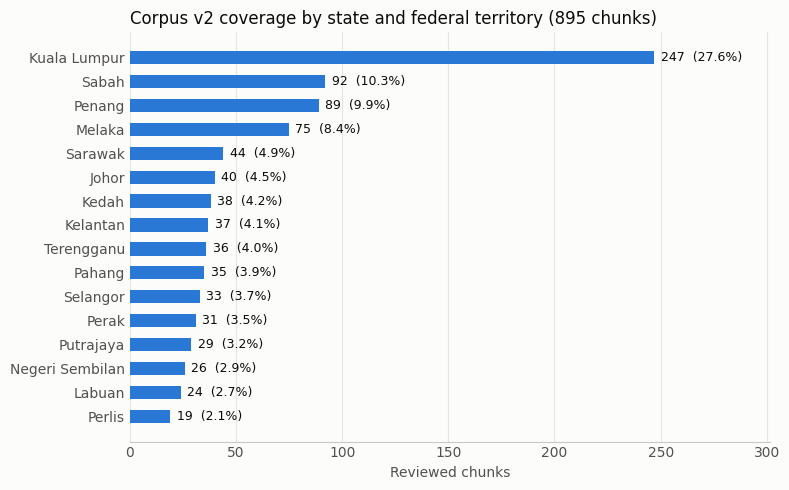

In [8]:
import matplotlib.pyplot as plt
STATES = ['Kuala Lumpur', 'Selangor', 'Putrajaya', 'Negeri Sembilan', 'Melaka', 'Johor', 'Perak', 'Penang',
          'Kedah', 'Perlis', 'Pahang', 'Terengganu', 'Kelantan', 'Sabah', 'Sarawak', 'Labuan']
TOPICS = {
    'Heritage & culture': r'(?i)\b(heritage|temple|mosque|church|colonial|historic|culture|cultural|museum|gallery)\b',
    'Food': r'(?i)\b(food|cuisine|dish|restaurant|hawker|nasi|satay|cafe|dining|eat)\b',
    'Nature & parks': r'(?i)\b(park|garden|forest|nature|lake|hill|waterfall|bird|island|beach|mount)\b',
    'Shopping': r'(?i)\b(shopping|mall|bazaar|market|boutique|retail)\b',
    'Opening hours stated': HOURS.pattern, 'Entry price stated': PRICE.pattern,
    'Disability access info': r'(?i)wheelchair|disabled|\boku\b|barrier-free|step-free',
}
rows = []
for s in STATES:
    docs = [d for d in unique_docs if d.metadata.get('state') == s]
    row = {'state': s, 'chunks': len(docs), 'share_%': round(len(docs) / len(unique_docs) * 100, 1),
           'with_page_ref': sum(d.metadata.get('page') is not None for d in docs)}
    for k, p in TOPICS.items():
        row[k] = sum(bool(re.search(p, d.page_content)) for d in docs)
    rows.append(row)
coverage = pd.DataFrame(rows)
print(coverage.to_string(index=False))
assert (coverage['chunks'] > 0).all(), 'A state has no chunks'
coverage.to_csv(BASE / 'docs' / 'week4_coverage_by_state.csv', index=False)

SERIES, INK, MUTED, SURFACE = '#2a78d6', '#0b0b0b', '#52514e', '#fcfcfb'
fig, ax = plt.subplots(figsize=(8, 5.0), facecolor=SURFACE); ax.set_facecolor(SURFACE)
order = coverage.sort_values('chunks')
bars = ax.barh(order['state'], order['chunks'], height=0.55, color=SERIES)
for b, v, pct in zip(bars, order['chunks'], order['share_%']):
    ax.text(b.get_width() + 3, b.get_y() + b.get_height() / 2, f'{v}  ({pct}%)', va='center', fontsize=9, color=INK)
ax.set_xlabel('Reviewed chunks', color=MUTED)
ax.set_title(f'Corpus v2 coverage by state and federal territory ({len(unique_docs)} chunks)', loc='left', color=INK)
ax.grid(axis='x', color='#e6e5e1', linewidth=0.8); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.spines['bottom'].set_color('#c9c8c3'); ax.tick_params(colors=MUTED, length=0)
ax.set_xlim(0, coverage['chunks'].max() * 1.22)
plt.tight_layout(); plt.savefig(BASE / 'docs' / 'week4_coverage_by_state.png', dpi=150); plt.show()


## 6 — Verify and download

In [9]:
with open(BASE / 'data' / 'chunks_clean_v2.pkl', 'rb') as f:
    reloaded = pickle.load(f)
rows_v2 = [json.loads(l) for l in open(BASE / 'data' / 'prepared_chunks_clean_v2.jsonl', encoding='utf-8') if l.strip()]
assert len(reloaded) == len(rows_v2) and all(a['text'] == b.page_content for a, b in zip(rows_v2, reloaded))
print('PASS: corpus v2 PKL and JSONL match —', len(rows_v2), 'chunks')
print('Ligatures left:', sum(bool(LIGATURE.search(r['text'])) for r in rows_v2),
      '| glyph-ID left:', sum('/gid' in r['text'] for r in rows_v2))

manifest = {'created': str(date.today()), 'method': 'paragraph-aware-char-500 (+map-label-filter for map guides)',
            'sources': inspect_rows, 'removed': len(removed), 'new_chunks_kept': len(new_docs),
            'kl_chunks': len(kl_docs), 'corpus_v2_chunks': len(unique_docs),
            'outputs': {p: hashlib.sha256((BASE / p).read_bytes()).hexdigest()
                        for p in ['data/processed/prepared_text_states.jsonl', 'data/prepared_chunks_clean_v2.jsonl']}}
(BASE / 'data' / 'week4_states_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Saved data/week4_states_manifest.json')

OUT = ['data/processed/prepared_text_states.jsonl', 'data/prepared_chunks_clean_v2.jsonl', 'data/chunks_clean_v2.pkl',
       'data/week4_states_manifest.json', 'docs/week4_states_validation_failures.csv', 'docs/week4_states_quarantine_log.csv',
       'docs/week4_states_duplicate_review.csv', 'docs/week4_coverage_by_state.csv', 'docs/week4_coverage_by_state.png']
stage = BASE / 'week4b_download'
if stage.exists(): shutil.rmtree(stage)
for p in OUT:
    (stage / p).parent.mkdir(parents=True, exist_ok=True); shutil.copy(BASE / p, stage / p)
    print(f'{p:46} {os.path.getsize(BASE / p):>8} bytes')
archive = shutil.make_archive(str(BASE / 'week4b_outputs'), 'zip', stage)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Not in Colab — download', archive, 'manually.')


PASS: corpus v2 PKL and JSONL match — 895 chunks
Ligatures left: 0 | glyph-ID left: 0
Saved data/week4_states_manifest.json
data/processed/prepared_text_states.jsonl        478494 bytes
data/prepared_chunks_clean_v2.jsonl              720146 bytes
data/chunks_clean_v2.pkl                         580578 bytes
data/week4_states_manifest.json                    5804 bytes
docs/week4_states_validation_failures.csv          4530 bytes
docs/week4_states_quarantine_log.csv               2016 bytes
docs/week4_states_duplicate_review.csv             2012 bytes
docs/week4_coverage_by_state.csv                    695 bytes
docs/week4_coverage_by_state.png                  97027 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>